# Access SARWAVE sea state

SARWAVE Sentinel-1 IW Level-2 products provide estimates of significant wave height and mean wave period from synthetic aperture radar observations, developed by Ifremer.

This example uses four 17.5 km intraburst scenes over the eastern Mediterranean from 23 to 26 January 2022, during Storm Elpis.

* Project resources: [SARWAVE](https://www.sarwave.org/resources)
* Original data source: [Ifremer 2022 Zarr archive](https://cerweb.ifremer.fr/datarmor/sarwave/diffusion/sar/iw/slc/l2/experimental_product_collection/v3.0/17.5km/uncompressed_zarr/2022/)
* Reference: [SARWAVE Sentinel-1 Experimental Dataset — Level-2 WAV](https://doi.org/10.12770/1b05fc41-e06e-4285-ad7b-b97f6f847e00)
* Product documentation: [SARWAVE Level-2 product description](https://cerweb.ifremer.fr/datarmor/sarwave/documentation/processor/sar/sarwaveifrproc/html/product_description.html)

In [ ]:
import pandas as pd
import xarray as xr

## Open one scene

Open the `intraburst` group for the IW2 swath on 23 January 2022. The dataset contains two-dimensional `latitude` and `longitude` coordinates for its tile grid. Data arrays stay lazy until needed for a plot or calculation.

In [ ]:
base = (
    "https://cerweb.ifremer.fr/datarmor/sarwave/diffusion/sar/iw/slc/l2/"
    "experimental_product_collection/v3.0/17.5km/uncompressed_zarr/2022/"
)
zarr_href = base + (
    "023/S1A_IW_WAV__2SDV_20220123T041601_20220123T041628_041583_04F232_1CB1_E11.SAFE/"
    "l2-s1a-iw2-wav-dv-20220123t041602-20220123t041627-041583-04f232-e11.zarr"
)

ds = xr.open_zarr(zarr_href, group="intraburst")
ds

## Plot significant wave height

Select `hs_most_likely`, in metres, and mask tiles where `land_flag` is not zero. Plot using the scene’s latitude and longitude coordinates.

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Keep tiles flagged as ocean. The mask stays lazy until plotting.
hs = ds.hs_most_likely.where(ds.land_flag == 0)
date = pd.Timestamp(ds.attrs["start_date"]).strftime("%d %B %Y")

fig, ax = plt.subplots(
    figsize=(9, 5),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
hs.plot(
    ax=ax,
    x="longitude",
    y="latitude",
    transform=ccrs.PlateCarree(),
    cmap="viridis",
    vmin=0,
    vmax=4,
    cbar_kwargs={"label": "Significant wave height (m)"},
)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray")
ax.coastlines("50m", linewidth=0.8)
ax.set_title(f"SARWAVE significant wave height — {date}")
plt.show()

## Scene statistics

Summarise significant wave height over the retained ocean tiles. Missing values are excluded.

In [ ]:
hs.to_series().describe().round(2)

## Open more scenes

Add one overpass from each of the next three days. Each scene has its own tile grid and footprint, so keep the datasets in a list.
Overpasses during the [Elpis](https://en.wikipedia.org/wiki/Storm_Elpis) storm period.

In [ ]:
urls = [
    base + (
        "024/S1A_IW_WAV__2SDV_20220124T155810_20220124T155837_041605_04F2EE_8D3C_E11.SAFE/"
        "l2-s1a-iw2-wav-dv-20220124t155812-20220124t155837-041605-04f2ee-e11.zarr"
    ),
    base + (
        "025/S1A_IW_WAV__2SDV_20220125T035944_20220125T040011_041612_04F326_A959_E11.SAFE/"
        "l2-s1a-iw2-wav-dv-20220125t035945-20220125t040011-041612-04f326-e11.zarr"
    ),
    base + (
        "026/S1A_IW_WAV__2SDV_20220126T154139_20220126T154207_041634_04F3F4_D55F_E11.SAFE/"
        "l2-s1a-iw2-wav-dv-20220126t154139-20220126t154207-041634-04f3f4-e11.zarr"
    )
]

datasets = [ds] + [xr.open_zarr(url, group="intraburst") for url in urls]
waves = [hs] + [d.hs_most_likely.where(d.land_flag == 0) for d in datasets[1:]]

## Map all four scenes

In [ ]:
fig, ax = plt.subplots(
    figsize=(10, 5),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
ax.set_extent([23, 37, 32.5, 39], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray")
ax.coastlines("50m", linewidth=0.8)

for wave in waves:
    im = wave.plot(
        ax=ax,
        x="longitude",
        y="latitude",
        transform=ccrs.PlateCarree(),
        cmap="viridis",
        vmin=0,
        vmax=4,
        add_colorbar=False,
        add_labels=False,
    )

fig.colorbar(im, ax=ax, label="Significant wave height (m)", pad=0.03)
ax.set_title("SARWAVE significant wave height — 23–26 January 2022")
plt.show()

## Compare scene statistics

Compare the ocean-tile count, mean and maximum significant wave height for each acquisition.

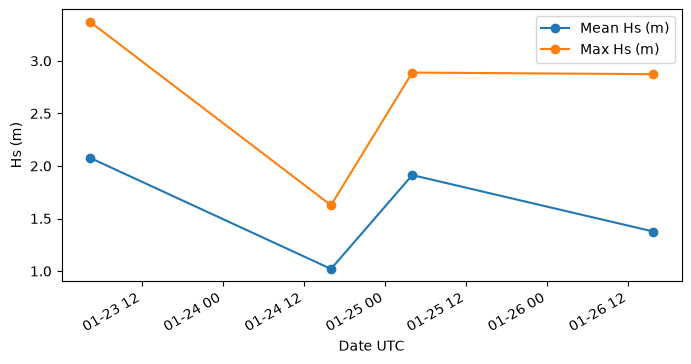

In [55]:
# Acquisition start times come from the product metadata, in UTC.
times = pd.to_datetime([d.attrs["start_date"] for d in datasets])

stats = pd.DataFrame({
    "Date UTC": pd.to_datetime(times),
    "Mean Hs (m)": [float(w.mean()) for w in waves],
    "Max Hs (m)": [float(w.max()) for w in waves],
})

stats.plot(x="Date UTC", marker="o", ylabel="Hs (m)", figsize=(8, 4))
plt.show()